# Setup

In [1]:
import sys

from Part_2.course22p2.miniai.datasets import show_image, inplace, DataLoaders

sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
import math, torch, matplotlib.pyplot as plt
import fastcore.all as fc
from collections.abc import Mapping
from operator import attrgetter
from functools import partial
from copy import copy

from torch import optim
import torch.nn.functional as F

from miniai.conv import *

from fastprogress import progress_bar, master_bar
import matplotlib as mpl
import torchvision.transforms.functional as TF
from contextlib import contextmanager
from torch import nn, tensor
from datasets import load_dataset, load_dataset_builder
from miniai.datasets import *
from miniai.conv import *
import logging
from fastcore.test import test_close

In [3]:
torch.set_printoptions(precision=2, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray'
logging.disable(logging.WARNING)

# Learner

In [4]:
x,y = 'image','label'
name = "fashion_mnist"
dsd = load_dataset(name)

In [5]:
@inplace
def transformi(b) : b[x] = [torch.flatten(TF.to_tensor(o)) for o in b[x]]

In [6]:
bs = 1024
tds = dsd.with_transform(transform=transformi)

In [7]:
dls = DataLoaders.from_dd(tds , bs , num_workers=0) # we made it like this because there are some noisy errors (not real errors) that appear when we increase the num_workers
dt = dls.train
xb,yb = next(iter(dt))
xb.shape , yb[:10]

(torch.Size([1024, 784]), tensor([5, 4, 9, 4, 3, 0, 6, 5, 7, 6]))

- `self.losses.append(self.loss*n)` --> that is to make sure that if there was a small batch at the end --> have the scale that is smaller that the bigger batchs
-` for self.num,self.batch in enumerate(dl): self.one_batch() ` --> `self.num` is for the callbacks later

    no_grad         → no gradients, still flexible
                      (batchnorm, dropout still behave like training)
    inference_mode  → no gradients, faster, read-only

    validation loop → no_grad
    production      → inference_mode

In [8]:
class Learner:
    def __init__(self,model,dls,loss_func,lr,opt_func=optim.SGD): fc.store_attr()
    def one_batch(self):
        self.xb,self.yb = to_device(self.batch)
        self.preds = self.model(self.xb)
        self.loss = self.loss_func(self.preds,self.yb)
        if self.model.training:
            self.loss.backward()
            self.opt.step() # self.opt is defined in fit()
            self.opt.zero_grad()
        with torch.no_grad(): self.calc_stats()

    def calc_stats(self):
        acc = ((torch.argmax(self.preds,dim=1) == self.yb).float().sum())*100
        self.accs.append(acc)
        n = len(self.xb)
        self.losses.append(self.loss*n)
        self.ns.append(n)

    def one_epoch(self,train):
        self.model.training = train
        dl = self.dls.train if train else self.dls.valid
        for self.num,self.batch in enumerate(dl): self.one_batch()
        n = sum(self.ns)
        print(f'EPOCH: {self.epoch} | LOSS: {sum(self.losses).item()/n:.2f} | ACC: {sum(self.accs)/n:.2f} | TRAINING: {self.model.training}')

    def fit(self,n_epochs):
        self.n_epochs,self.accs,self.losses,self.ns =n_epochs,[],[],[]
        self.model.to(def_device)
        self.opt = self.opt_func(self.model.parameters() , self.lr)
        for self.epoch in range(n_epochs):
            self.one_epoch(train=True)
            with torch.no_grad():self.one_epoch(train=False)

In [9]:
m,nh = 28*28 , 50
model = nn.Sequential(nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10))

In [10]:
learn = Learner(model,dls,F.cross_entropy,lr=0.2)
learn.fit(2)

EPOCH: 0 | LOSS: 1.18 | ACC: 59.86 | TRAINING: True
EPOCH: 0 | LOSS: 1.12 | ACC: 61.34 | TRAINING: False
EPOCH: 1 | LOSS: 0.93 | ACC: 67.41 | TRAINING: True
EPOCH: 1 | LOSS: 0.91 | ACC: 68.08 | TRAINING: False


# Basic Callbacks Learner

In [11]:
# making a classes for error raising so that we can stop anything using try: ... , except: ...
class CancelFitException(Exception): pass
class CancelBatchException(Exception): pass
class CancelEpochException(Exception): pass

In [12]:
# make a that makes the order of the cb 0 by default
class Callback():
    order = 0
    _fwd = 'model','opt','batch','epoch'

    def __getattr__(self, name):
        if name in self._fwd: return getattr(self.learn, name)
        raise AttributeError(name)

    def __setattr__(self, name, val):
        if name in self._fwd: warn(f'Setting {name} in callback. Did you mean to set `self.learn.{name}`?')
        super().__setattr__(name, val)

    @property
    def training(self): return self.model.training

In [13]:
# make run_cbs function
def run_cbs(cbs , method_nm , learn=None):
    for cb in sorted(cbs,key=attrgetter('order')):
        method = getattr(cb,method_nm,None) # None if method doesn't exist
        if method is not None: method(learn)

-`learn` here is the object, and we make it `None` by default -> if we don't have object (let's say testing the callbacks)

    - getattr(obj, 'name')     → gets ONE attr, one time, not reusable
    - attrgetter('name','age') → creates callable, reusable, multiple attrs

    - getattr    ↔  obj['key']      (one shot)
    - attrgetter ↔  itemgetter      (reusable callable)
      but for ATTRIBUTES (dot access) not KEYS (bracket access)

In [14]:
# lets try making a cb
class CompletionCB(Callback):
    def before_fit(self,learn): self.count = 0 # learn in (self,learn) -> run_cbs always pass it
    def after_batch(self,learn): self.count += 1
    def after_fit(self,learn): print(f'completed batchs: {self.count}')

In [15]:
cbs = [CompletionCB()]
run_cbs(cbs, 'before_fit')
run_cbs(cbs, 'after_batch');run_cbs(cbs, 'after_batch') # ; -> just to save vertical space
run_cbs(cbs, 'after_fit')

completed batchs: 2


In [16]:
# create the learner
class Learner():
    def __init__(self, model, dls, loss_func, lr, cbs, opt_func=optim.SGD): fc.store_attr()

    def one_batch(self):
        self.preds = self.model(self.batch[0])
        self.loss = self.loss_func(self.preds,self.batch[1])
        if self.model.training:
            self.loss.backward()
            self.opt.step()
            self.opt.zero_grad()

    def one_epoch(self,train):
        self.model.train(train) # this is the torch model.train(), where .train(False) = .eval()
        self.dl = self.dls.train if train else self.dls.valid
        try:
            self.callback('before_epoch') # self.callback() is defined in last function in class
            for self.iter,self.batch in enumerate(self.dl):
                try:
                    self.callback('before_batch')
                    self.one_batch()
                    self.callback('after_batch')
                except CancelBatchException : pass
            self.callback('after_epoch')
        except CancelEpochException : pass

    def fit(self,n_epochs):
        self.n_epochs,self.epochs = n_epochs,range(n_epochs)
        self.opt = self.opt_func(self.model.parameters() , self.lr)
        try:
            self.callback('before_fit')
            for self.epoch in self.epochs:
                self.one_epoch(train=True)
                self.one_epoch(train=False)
            self.callback('after_fit')
        except CancelFitException : pass

    def callback(self,method_name): run_cbs(self.cbs,method_name,learn=self)

**What Changed**:

        LEARNER 1:                          LEARNER 2:
    ────────────────────────────────    ────────────────────────────────
    one_batch:
      to_device() hardcoded        →      DeviceCB does it
      calc_stats() hardcoded       →      MetricsCB does it
      self.xb, self.yb             →      self.batch[0], self.batch[1]

    one_epoch:
      print() hardcoded            →      MetricsCB logs it
      self.model.training = train  →      self.model.train(train)

    fit:
      self.model.to(device)        →      DeviceCB does it
      self.accs,self.losses,self.ns→      MetricsCB tracks it
      torch.no_grad() on valid     →      handled elsewhere

In [17]:
m,nh = 28*28,50
def get_model(): return nn.Sequential(nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10))

In [18]:
model = get_model()
learn = Learner(model, dls, F.cross_entropy, lr=0.2, cbs=[CompletionCB()])
learn.fit(1)

completed batchs: 64


In [19]:
# make a CB that let us run just on batch
class SingleBatchCB(Callback):
    order = 1
    def after_batch(self, learn): raise CancelFitException() # FIT cancel not batch

In [20]:
learn = Learner(get_model(), dls, F.cross_entropy, lr=0.2, cbs=[SingleBatchCB(), CompletionCB()])
learn.fit(1)

It didn't print Batches because CompletionCB Print after_fit.

# Meterics

ALL THREE are identical in Python 3

    class Foo:        # no brackets
    class Foo():      # empty brackets
    class Foo(object): # explicitly inherits from object

    inheriting from something → brackets required ✓
    not inheriting            → brackets optional

In [21]:
class Metric:
    def __init__(self): self.reset() # to initialize the list so we use reset (cleaner)
    def reset(self): self.vals,self.ns = [],[]
    def add(self,inp,targs=None,n=1): # we make -> n=size_of_batch later
        self.last = self.calc(inp,targs)
        self.vals.append(self.last)
        self.ns.append(n)
    @property  # just makes use call fn as att , self.value() -> self.value
    def value(self):
        ns = tensor(self.ns)
        return ((tensor(self.vals)*ns).sum())/(ns.sum())
    def calc(self,inp,targs=None): return inp # just a base (we overwrite it when make metric)

In [22]:
class Accuracy(Metric):
    def calc(self,inps,targs): return (inps==targs).float().mean()

In [23]:
# try it
acc = Accuracy()
acc.add(tensor([0, 1, 2, 0, 1, 2]), tensor([0, 1, 1, 2, 1, 0]))
acc.add(tensor([1, 1, 2, 0, 1]), tensor([0, 1, 1, 2, 1]))
acc.value

tensor(0.45)

In [24]:
# use it to get the weighted average
loss = Metric()
loss.add(0.6, n=32)
loss.add(0.9, n=2)
loss.value, round((0.6*32+0.9*2)/(32+2), 2)

(tensor(0.62), 0.62)

# Some callbacks

In [25]:
from torcheval.metrics import MulticlassAccuracy,Mean

In [26]:
metric = MulticlassAccuracy()
metric.update(tensor([0, 2, 1, 3]), tensor([0, 1, 2, 3])) # = add()
metric.compute() # = value()

tensor(0.50)

In [27]:
metric.reset()
metric.compute()

tensor(nan)

In [28]:
# fn to move everything to the cpu
def to_cpu(x):
    if isinstance(x,Mapping): return {k: to_cpu(v) for k,v in x.items()}
    if isinstance(x,list): return [to_cpu(v) for v in x]
    if isinstance(x,tuple): return tuple(to_cpu(v) for v in x)
    res = x.detach().cpu()  # detach -> removes the gradient history
    return res.float() if res.dtype==torch.float16 else res

at  `return res.float() if res.dtype==torch.float16 else res`
- GPU training  → float16 (fast, memory efficient)
- display/numpy → float32 (required)

- **matplotlib, numpy, display functions** -> CANNOT handle tensors with gradient history
- `detach()` makes it a clean plain tensor ✅

Why not to_device(cpu):

    to_cpu() does EXTRAS:
    1. detach()  → free gradient graph
    3. float()   → float16 → float32 (for matplotlib/numpy)

    to_device('cpu') does NONE of these extras
    thats why to_cpu() exists ✅

In [29]:
class MetricsCB(Callback):
    def __init__(self,*ms,**metrics):
        for o in ms : metrics[type(o),__name__] = o
        self.metrics = metrics
        self.all_metrics = copy(self.metrics)
        self.all_metrics['loss'] = self.loss = Mean() # makes a like a calculator for the mean()
    def before_fit(self,learn): learn.metrics = self
    def before_epoch(self,learn): [o.reset() for o in self.all_metrics.values()]
    def after_batch(self,learn):
        x,y,*_ = to_cpu(learn.batch)
        for m in self.metrics.values(): m.update(to_cpu(learn.preds) , y)
        self.loss.update(to_cpu(learn.loss),weight=len(x))
    def after_epoch(self,learn):
        log = {k: f'{v.compute():.3f}' for k,v in self.all_metrics.items()}
        log['epoch'] = learn.epoch
        log['train'] = 'train' if learn.model.training else 'eval'
        self._log(log)
    def _log(self,d): print(d)

- ` copy()  `   → new dict, shared objects  **(shallow)**
- `deepcopy()` → new dict, new objects     **(deep)**

here we WANT shallow
so Accuracy stays shared between metrics and all_metrics,
updating metrics['Accuracy'] → all_metrics['Accuracy'] also updated ✅

In Dictionary looping:

    dict            → keys only
    dict.values()   → values only
    dict.items()    → key + value

At after_epoch:

    v.compute()              # → tensor(0.92341682)  raw tensor
    f'{v.compute():.3f}'     # → '0.923'             clean string
    #              ↑
    #          .3f = 3 decimal places

    # for printing/logging you want clean readable string

Why to_cpu:

    GPU → training  (fast)
    CPU → metrics   (safe, consistent, no device mismatch)
    tensor → string = must be on CPU first (at log=...)

    main rule:
    if two tensors interact → must be on SAME device
    easiest solution → move everything to CPU for metrics ✅

In [30]:
# Make a device CB
class DeviceCB(Callback):
    def __init__(self,device=def_device): fc.store_attr()
    def before_fit(self,learn):
        if hasattr(learn.model,'to'): learn.model.to(self.device)
    def before_batch(self,learn): learn.batch = to_device(learn.batch,device=self.device)

- @`before fit()` -> hasattr check = does this model have `.to()` method?, almost always yes, but safe to check ✅ | before fitting beacause model stays on the GPU during training
- @`before_batch` -> move EACH batch to GPU just before it's used, not all at once

In [31]:
model = get_model()
metrics = MetricsCB(accuracy=MulticlassAccuracy())
learn = Learner(model, dls, F.cross_entropy, lr=0.2, cbs=[DeviceCB(), metrics])
learn.fit(2)

{'accuracy': '0.611', 'loss': '1.176', 'epoch': 0, 'train': 'train'}
{'accuracy': '0.677', 'loss': '0.857', 'epoch': 0, 'train': 'eval'}
{'accuracy': '0.739', 'loss': '0.722', 'epoch': 1, 'train': 'train'}
{'accuracy': '0.763', 'loss': '0.680', 'epoch': 1, 'train': 'eval'}


# Flexible Learner

In [32]:
class Learner():
    def __init__(self,model,dls=(0,),loss_func=F.mse_loss,opt_func=optim.SGD,lr=0.1,cbs=None): cbs=fc.L(cbs) ;fc.store_attr()

    @contextmanager
    def cb_ctx(self,nm):
        try:
            self.callback(f'before_{nm}')
            yield
            self.callback(f'after_{nm}')
        except globals()[f'Cancel{nm.title()}Exception'] : pass # Title just make 1st letter Capital
        finally: self.callback(f'cleanup_{nm}')

    def one_epoch(self,train):
        self.model.train(train)
        self.dl = self.dls.train if train else self.dls.valid
        with self.cb_ctx('epoch'):
            for self.iter , self.batch in enumerate(self.dl):
                with self.cb_ctx('batch'):
                    self.predict()
                    self.get_loss()
                    if self.training:
                        self.backward()
                        self.step()
                        self.zero_grad()

    def fit(self, n_epochs=1, train=True, valid=True, cbs=None, lr=None):
        cbs = fc.L(cbs)  # this is local variable
        for cb in cbs: self.cbs.append(cb)  # MANUALLY append
        try:
            self.n_epochs = n_epochs
            self.epochs = range(n_epochs)
            self.opt = self.opt_func(self.model.parameters(), self.lr if lr is None else lr)
            with self.cb_ctx('fit'):
                for self.epoch in self.epochs:
                    if train: self.one_epoch(True)
                    if valid: torch.no_grad()(self.one_epoch)(False)
        finally:
            for cb in cbs: self.cbs.remove(cb) # MANUALLY remove

    def __getattr__(self, nm):
        if nm in ('predict','get_loss','backward','step','zero_grad') : return partial(self.callback,nm)
        raise AttributeError(nm)

    def callback(self,method_nm): run_cbs(self.cbs,method_nm,self)

    @property
    def training(self): return self.model.training

**fc.L**

    normal list() crashes on None and single objects (not iterable(can't be indexed))
    fc.L handles everything:
    None         → []
    SingleCB()   → [SingleCB()]
    [CB1, CB2]   → [CB1, CB2]

**Context Manager**

    allows you to use WITH statement
    WITH = "run code in indentation
            when indentation ends → i know it ended
            → resume after yield (yield
            → run after_xxx
            → run finally/cleanup no matter what"

    replaces writing try/except/finally
    everywhere manually → one clean with block

**globals()**

    Dictionary of everything defined in file
    used to BUILD exception name from string:
    'batch' → 'CancelBatchException'
    so one cb_ctx handles batch/epoch/fit
    instead of 3 separate try/excepts

**getattr**

    runs when attribute DOESNT EXIST
    MUST return something callable
    because () will be called on it:

    self.predict()
        │
        __getattr__ returns partial(self.callback, 'predict') # pre-fills self.callback
                                                                with 'predict' as first
                                                                argument
        │
        () calls it → callback fires ✓

    if you just run callback inside __getattr__
    without returning → returns None → () on None → CRASH

**training property**

    shorthand:
    self.training = self.model.training
    used in multiple places so worth the shortcut

In [33]:
class TrainCB(Callback):
    def __init__(self,n_inp=1):self.n_inp = n_inp
    def predict(self,learn): learn.preds = learn.model(*learn.batch[:self.n_inp])
    def get_loss(self,learn): learn.loss = learn.loss_func(learn.preds,*learn.batch[self.n_inp:])
    def backward(self,learn): learn.loss.backward()
    def step(self,learn): learn.opt.step()
    def zero_grad(self,learn): learn.opt.zero_grad()

    slice first → then unpack
    batch[:n_inp] → *batch[:n_inp]

    n_inp = number of inputs your model takes
    makes TrainCB flexible for any model:
    n_inp=1 → model(image)
    n_inp=2 → model(image, mask)
    and also that can help if the model have more than one output

In [34]:
class ProgressCB(Callback):
    order = MetricsCB.order+1
    def __init__(self,plot=False): self.plot = plot
    def before_fit(self,learn):
        learn.epochs = self.mbar = master_bar(learn.epochs)
        self.first = True
        if hasattr(learn,'metrics'): learn.metrics._log = self._log
        self.losses=[]
        self.val_losses = []

    def _log(self,d):
        if self.first:
            self.mbar.write(list(d),table=True)
            self.first = False
        self.mbar.write(list(d.values()),table=True)

    def before_epoch(self,learn): learn.dl = progress_bar(learn.dl,leave=False,parent=self.mbar)

    def after_batch(self,learn):
        learn.dl.comment = f'{learn.loss:.3f}'
        if self.plot and hasattr(learn,'metrics') and learn.training:
            self.losses.append(learn.loss.item())
            if self.val_losses: self.mbar.update_graph([[fc.L.range(self.losses), self.losses],[fc.L.range(learn.epoch).map(lambda x: (x+1)*len(learn.dls.train)), self.val_losses]])

    def after_epoch(self, learn):
        if not learn.training:
            if self.plot and hasattr(learn, 'metrics'):
                self.val_losses.append(learn.metrics.all_metrics['loss'].compute())
                self.mbar.update_graph([[fc.L.range(self.losses), self.losses],[fc.L.range(learn.epoch+1).map(lambda x: (x+1)*len(learn.dls.train)), self.val_losses]])

why does the orders feel as if they are local variables and we dont asign to self.order?

- because order is **class level** = always exists
              even before any instance created ✓

accuracy,loss,epoch,train
0.593,1.180,0,train
0.684,0.805,0,eval
0.742,0.712,1,train
0.755,0.654,1,eval


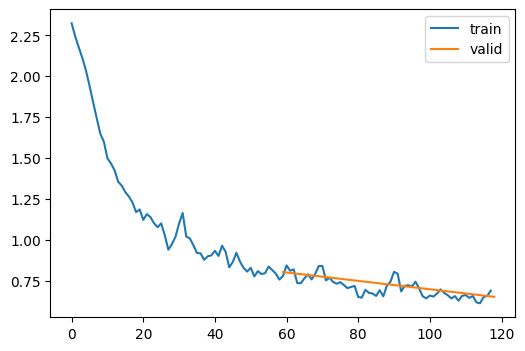

In [35]:
model = get_model()
metrics = MetricsCB(accuracy=MulticlassAccuracy())
cbs = [TrainCB(), DeviceCB(), metrics, ProgressCB(plot=True)]
learn = Learner(model, dls, F.cross_entropy, lr=0.2, cbs=cbs)
learn.fit(2)

# Making an Learner updated version

- becuase context manager have bug , so we make a custom decorator our sleves

In [36]:
class with_cbs():
    def __init__(self,nm): self.nm = nm
    def __call__(self,f):
        def _f(o, *args, **kwargs): # we make o -> self when used
            try:
                o.callback(f'before_{self.nm}')
                f(o, *args, **kwargs)
                o.callback(f'after_{self.nm}')
            except globals()[f'Cancel{self.nm.title()}Exception']: pass
            finally: o.callback(f'cleanup_{self.nm}')
        return _f

In [37]:
class Learner():
    def __init__(self, model, dls=(0,), loss_func=F.mse_loss, lr=0.1, cbs=None, opt_func=optim.SGD):
        cbs = fc.L(cbs)
        fc.store_attr()

    @with_cbs('batch')
    def _one_batch(self):
        self.predict()
        self.callback('after_predict') # NEW (more flexibility)
        self.get_loss()
        self.callback('after_loss') # NEW
        if self.training:
            self.backward()
            self.callback('after_backward') # NEW
            self.step()
            self.callback('after_step') # NEW
            self.zero_grad()

    @with_cbs('epoch')
    def _one_epoch(self): # _... -> private (not the thing to call, just a sign)
        for self.iter,self.batch in enumerate(self.dl): self._one_batch()

    def one_epoch(self, training):
        self.model.train(training)
        self.dl = self.dls.train if training else self.dls.valid
        self._one_epoch()

    @with_cbs('fit')
    def _fit(self, train, valid):
        for self.epoch in self.epochs:
            if train: self.one_epoch(True)
            if valid: torch.no_grad()(self.one_epoch)(False)

    def fit(self, n_epochs=1, train=True, valid=True, cbs=None, lr=None):
        cbs = fc.L(cbs)
        for cb in cbs: self.cbs.append(cb)
        try:
            self.n_epochs = n_epochs
            self.epochs = range(n_epochs)
            if self.opt_func: self.opt = self.opt_func(self.model.parameters(), self.lr if lr is None else lr)
            self._fit(train, valid)
        finally:
            for cb in cbs: self.cbs.remove(cb)

    def __getattr__(self, name):
        if name in ('predict','get_loss','backward','step','zero_grad'): return partial(self.callback, name)
        raise AttributeError(name)

    def callback(self, method_nm): run_cbs(self.cbs, method_nm, self)

    @property
    def training(self): return self.model.training

accuracy,loss,epoch,train
0.615,1.184,0,train
0.718,0.778,0,eval


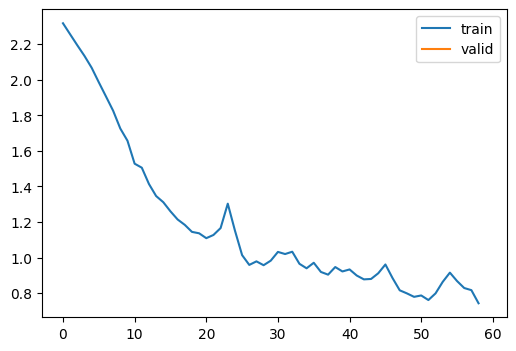

In [38]:
model = get_model()

metrics = MetricsCB(accuracy=MulticlassAccuracy())
cbs = [TrainCB(), DeviceCB(), metrics, ProgressCB(plot=True)]
learn = Learner(model, dls, F.cross_entropy, lr=0.2, cbs=cbs)
learn.fit(1)

# TrainLearner and MomentumLearner

here We are making the thing is using inheritance not callbacks just to to show the flexibility that we can also do it using inheritance, but it's better if we did it using callbacks

In [39]:
# instead of the TrainCB
class TrainLearner(Learner):
    def predict(self): self.preds = self.model(self.batch[0])
    def get_loss(self): self.loss = self.loss_func(self.preds, self.batch[1])
    def backward(self): self.loss.backward()
    def step(self): self.opt.step()
    def zero_grad(self): self.opt.zero_grad()

In [40]:
# new method that doesnt (make grad = 0) with each update , but lower it by momentum (that is in case the (momentum < 1)
class MomentumLearner(TrainLearner):
    def __init__(self, model, dls, loss_func, lr=None, cbs=None, opt_func=optim.SGD, mom=0.85):
        self.mom = mom
        super().__init__(model, dls, loss_func, lr, cbs, opt_func)

    def zero_grad(self):
        with torch.no_grad():
            for p in self.model.parameters(): p.grad *= self.mom

In [41]:
# another way for the momentum learner and continue using the TrainCB

# class MomentumCB(TrainCB):
#     def __init__(self, mom=0.85, n_inp=1):
#         super().__init__(n_inp=n_inp)  # ← pass n_inp to TrainCB
#         self.mom = mom
#
#     def zero_grad(self, learn):        # ← override ONLY this
#         with torch.no_grad():
#             for p in learn.model.parameters():
#                 p.grad *= self.mom

`super()` = "call the PARENT class"

    WITHOUT super():
    class MomentumLearner(TrainLearner):
        def __init__(self, ...):
            self.mom = mom
            self.model = model      ← repeating
            self.dls = dls          ← all of
            self.loss_func = loss   ← Learner's
            self.lr = lr            ← __init__
            self.cbs = fc.L(cbs)   ← again!
            # DRY violation ✗

    WITH super():
    class MomentumLearner(TrainLearner):
        def __init__(self, ...):
            self.mom = mom
            super().__init__(...)   ← parent does it ✓
            # DRY ✓

accuracy,loss,epoch,train
0.673,0.945,0,train
0.785,0.592,0,eval


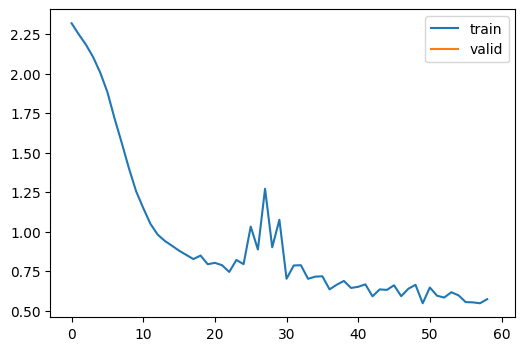

In [42]:
metrics = MetricsCB(accuracy=MulticlassAccuracy())
cbs = [DeviceCB(), metrics, ProgressCB(plot=True)]
learn = MomentumLearner(get_model(), dls, F.cross_entropy, lr=0.1, cbs=cbs)
learn.fit(1)

# LRFinderCB

In [44]:
class LRFinderCB(Callback):
    def __init__(self,lr_mult=1.3): fc.store_attr()
    def before_fit(self,learn):
        self.lrs , self.losses = [],[]
        self.min = math.inf # infinity
    def after_batch(self,learn):
        if not learn.training : raise CancelEpochException() # we make the lr finder in the training
        self.lrs.append(learn.opt.param_groups[0]['lr'])
        loss = to_cpu(learn.loss)
        self.losses.append(loss)
        if loss < self.min : self.min = loss
        if loss > self.min*3 : raise CancelFitException()
        for g in learn.opt.param_groups : g['lr'] *= self.lr_mult

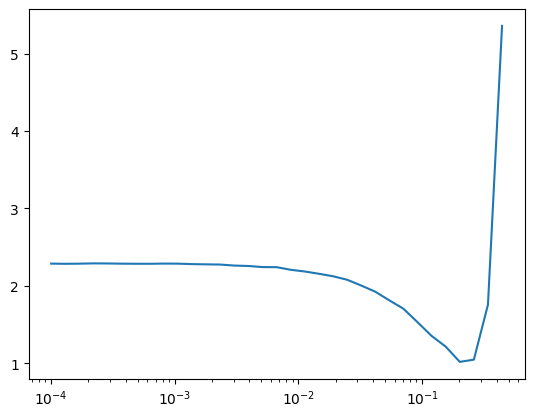

In [45]:
lrfind = LRFinderCB()
cbs = [DeviceCB(), lrfind]
learn = MomentumLearner(get_model(), dls, F.cross_entropy, lr=1e-4, cbs=cbs)
learn.fit(1)
plt.plot(lrfind.lrs, lrfind.losses)
plt.xscale('log')

Here we are going to make a pytorch version

    VERSION 1 (manual):               VERSION 2 (ExponentialLR):
    ─────────────────────────         ─────────────────────────
    lr_mult=1.3                        gamma=1.3        ← same thing, different name
    max_mult hardcoded = 3             max_mult=3       ← now configurable ✓

    for g in learn.opt.param_groups:   self.sched = ExponentialLR(learn.opt, self.gamma)
        g['lr'] *= self.lr_mult        self.sched.step()
        (you do it yourself)           (pytorch does it for you ✓)


In [46]:
from torch.optim.lr_scheduler import ExponentialLR

In [47]:
class LRFinderCB(Callback):
    def __init__(self,gamma=1.3,max_mult=3): fc.store_attr()
    def before_fit(self,learn):
        self.sched = ExponentialLR(learn.opt, self.gamma)
        self.lrs,self.losses = [],[]
        self.min = math.inf
    def after_batch(self, learn):
        if not learn.training: raise CancelEpochException()
        self.lrs.append(learn.opt.param_groups[0]['lr'])
        loss = to_cpu(learn.loss)
        self.losses.append(loss)
        if loss < self.min: self.min = loss
        if math.isnan(loss) or (loss > self.min*self.max_mult): # added also if nan (loss explode)
            raise CancelFitException()
        self.sched.step()

    def cleanup_fit(self, learn): # a plot CB to be called after fitting
        plt.plot(self.lrs, self.losses)
        plt.xscale('log')

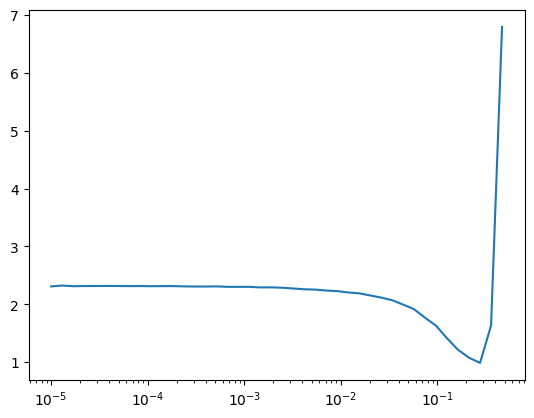

In [50]:
cbs = [DeviceCB()]
learn = MomentumLearner(get_model(), dls, F.cross_entropy, lr=1e-5, cbs=cbs)
learn.fit(3, cbs=LRFinderCB())

In [51]:
# make it shorter and attach it to the learner
@fc.patch
def lr_find(self:Learner, gamma=1.3, max_mult=3, start_lr=1e-5, max_epochs=10):
    self.fit(max_epochs, lr=start_lr, cbs=LRFinderCB(gamma=gamma, max_mult=max_mult))

- `Learner.lr_find = lr_find`
- `@fc.patch`

        both work identically ✓
        fc.patch = fancy one liner
        manual   = explicit and obvious

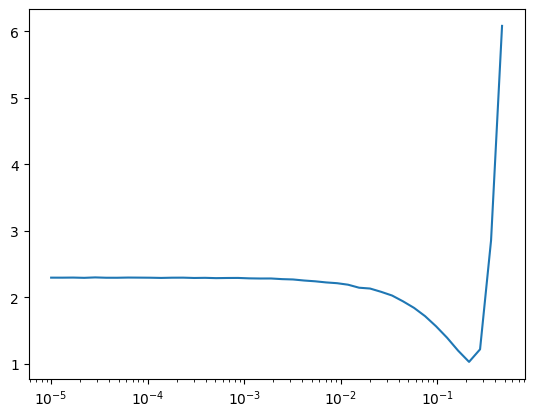

In [52]:
MomentumLearner(get_model(), dls, F.cross_entropy, cbs=cbs).lr_find()